Sentinel-1 SAR Oil Spill Pipeline & Full Kaggle Dataset Benchmark

In [1]:
import os
import sys
import json
import time
import hashlib
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import label, center_of_mass

# Suppress verbose TensorFlow logs
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf

print('TensorFlow Version:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPUs Available:', gpus)
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print('[✓] GPU Memory Growth Enabled on:', gpus[0].name)
    except Exception as e:
        print('[!] GPU Note:', e)


TensorFlow Version: 2.21.0
GPUs Available: []


In [2]:
# Resolve Project Paths
here = Path.cwd().resolve()
ROOT = None
for candidate in [here, here.parent, *here.parents]:
    if (candidate / 'ml').is_dir() and (candidate / 'kaggle').is_dir():
        ROOT = candidate
        break

if ROOT is None:
    ROOT = here

KAGGLE_DIR = ROOT / 'kaggle' / 'data'
MODELS_DIR = ROOT / 'ml' / 'models'
RESULTS_DIR = ROOT / 'ml' / 'results'

print(f'Project Root : {ROOT}')
print(f'Kaggle Data  : {KAGGLE_DIR} (Exists: {KAGGLE_DIR.exists()})')
print(f'Models Dir   : {MODELS_DIR} (Exists: {MODELS_DIR.exists()})')

# Discover all Kaggle Sentinel-1 SAR tiles
c1_images = sorted(list((KAGGLE_DIR / 'Class_1').glob('*.jpg')))
c0_images = sorted(list((KAGGLE_DIR / 'Class_0').glob('*.jpg')))
total_images = len(c1_images) + len(c0_images)

print(f'Class_1 (Confirmed Spills) : {len(c1_images):,} images')
print(f'Class_0 (Look-Alikes)      : {len(c0_images):,} images')
print(f'Total Dataset Size         : {total_images:,} images (2:1 Real-World Imbalance)')


Project Root : C:\Users\navjo\OneDrive\Desktop\maris
Kaggle Data  : C:\Users\navjo\OneDrive\Desktop\maris\kaggle\data (Exists: True)
Models Dir   : C:\Users\navjo\OneDrive\Desktop\maris\ml\models (Exists: True)
Class_1 (Confirmed Spills) : 1,843 images
Class_0 (Look-Alikes)      : 3,695 images
Total Dataset Size         : 5,538 images (2:1 Real-World Imbalance)


In [3]:
# Production Model: ResNet50V2 Attention U-Net (v2) - Highest Project Performance
MODEL_PATH = MODELS_DIR / 'final_resnet_attention_unet.keras'

if not MODEL_PATH.exists():
    for alt in ['best_resnet_attention_unet.keras', 'best_attention_unet.keras']:
        if (MODELS_DIR / alt).exists():
            MODEL_PATH = MODELS_DIR / alt
            break

def dice_score(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

def iou_score(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

def focal_tversky_loss(y_true, y_pred, alpha=0.5, beta=0.5, gamma=0.75, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred)
    fp = tf.reduce_sum((1.0 - y_true) * y_pred)
    fn = tf.reduce_sum(y_true * (1.0 - y_pred))
    tversky = (tp + smooth) / (tp + alpha * fp + beta * fn + smooth)
    return tf.pow(1.0 - tversky, gamma)

print(f'[*] Loading Production Model from: {MODEL_PATH.name}...')
model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={
        'dice_score': dice_score,
        'iou_score': iou_score,
        'focal_tversky_loss': focal_tversky_loss
    },
    compile=False
)
print(f'[✓] Loaded Model: {model.name} | Total Parameters: {model.count_params():,}')


[*] Loading Production Model from: final_resnet_attention_unet.keras...
[✓] Loaded Model: ResNet50V2_Attention_UNet | Total Parameters: 45,841,669


In [4]:
# =========================================================================
# COMPLETE MARIS 4-STAGE PIPELINE ENGINE
# Exact functional parity with ml/run_kaggle_pipeline.py
# =========================================================================

MEAN = np.array([0.4243585, 0.4243585, 0.4243585], dtype=np.float32)
STD  = np.array([0.2139608, 0.2139608, 0.2139608], dtype=np.float32)
IMG_SIZE = (256, 256)

def preprocess_sar(image_path):
    raw_img = Image.open(image_path).convert('RGB').resize(IMG_SIZE)
    img_array = np.array(raw_img, dtype=np.float32) / 255.0
    normalized = (img_array - MEAN) / STD
    tensor = np.expand_dims(normalized, axis=0)
    return raw_img, tensor

def extract_sar_morphometrics(binary_mask, raw_img_array):
    """
    Stage 2a: Computes Area (km2), Principal-Axis Aspect Ratio,
    Radar Damping Ratio (dB), Centroid, and Bonn Agreement Volume (MT).
    """
    slick_pixels = int(np.sum(binary_mask))
    total_pixels = binary_mask.size
    coverage_pct = (slick_pixels / total_pixels) * 100.0
    area_km2 = slick_pixels * 0.0001 # 10m x 10m ground resolution

    labeled_mask, num_features = label(binary_mask)
    if num_features == 0 or slick_pixels == 0:
        return {
            'slick_pixels': 0, 'coverage_pct': 0.0, 'area_km2': 0.0,
            'aspect_ratio': 0.0, 'damping_ratio_db': 0.0, 'centroid_pixel': (128.0, 128.0),
            'bonn_volume_mt': (0.0, 0.0)
        }

    sizes = [np.sum(labeled_mask == i) for i in range(1, num_features + 1)]
    dominant_id = int(np.argmax(sizes)) + 1
    dom_mask = (labeled_mask == dominant_id)
    cy, cx = center_of_mass(dom_mask)

    y_coords, x_coords = np.where(dom_mask)
    if len(y_coords) > 5:
        coords = np.vstack([x_coords - cx, y_coords - cy])
        cov = np.cov(coords)
        evals, _ = np.linalg.eig(cov)
        evals = np.sort(np.real(evals))[::-1]
        aspect_ratio = float(np.sqrt(max(evals[0], 1e-5) / max(evals[1], 1e-5))) if evals[1] > 0 else 1.0
    else:
        aspect_ratio = 1.0

    sea_pixels = raw_img_array[binary_mask == 0]
    slick_vals = raw_img_array[binary_mask == 1]
    sea_mean = np.mean(sea_pixels) if len(sea_pixels) > 0 else 128.0
    slick_mean = np.mean(slick_vals) if len(slick_vals) > 0 else 1.0
    damping_ratio_db = float(10.0 * np.log10(max(sea_mean, 1.0) / max(slick_mean, 1.0)))

    # Illustrative volume range for 50-500 micrometre film thickness, density 0.85 t/m3.
    # NOTE: not a Bonn Code 2-3 range, and chip areas assume 10 m pixels (unverified); not reported.
    vol_min_m3 = (area_km2 * 1e6) * 0.00005
    vol_max_m3 = (area_km2 * 1e6) * 0.00050
    bonn_min_mt = vol_min_m3 * 0.85
    bonn_max_mt = vol_max_m3 * 0.85

    return {
        'slick_pixels': slick_pixels,
        'coverage_pct': round(coverage_pct, 2),
        'area_km2': round(area_km2, 4),
        'aspect_ratio': round(aspect_ratio, 2),
        'damping_ratio_db': round(damping_ratio_db, 2),
        'centroid_pixel': (round(float(cx), 1), round(float(cy), 1)),
        'bonn_volume_mt': (round(bonn_min_mt, 2), round(bonn_max_mt, 2))
    }

def classify_slick_feature(metrics):
    """Stage 2b: Physics-informed discrimination of real slicks vs look-alikes."""
    px = metrics['slick_pixels']
    ar = metrics['aspect_ratio']
    damping = metrics['damping_ratio_db']
    cov = metrics.get('coverage_pct', 0.0)

    if px < 35:
        return 'NEGATIVE / CLEAN WATER', 'DISMISS (No slick detected)'
    elif cov > 10.0:
        return 'PROBABLE LOOK-ALIKE (Low-Wind Zone / Calm Sea)', f'SUPPRESS ALERT (Diffuse calm sea covering {cov:.1f}% of frame)'
    elif ar < 1.60:
        return 'PROBABLE LOOK-ALIKE (Algal Bloom / Biogenic Film)', f'SUPPRESS ALERT (Non-linear biogenic feature, AR={ar:.2f})'
    elif damping < 0.50:
        return 'PROBABLE LOOK-ALIKE (Faint Ambient Contrast)', f'SUPPRESS ALERT (Weak radar damping {damping:.2f} dB)'
    else:
        return 'CONFIRMED HYDROCARBON SPILL (Active Alert)', f'DISPATCH INTERCEPTION (Vessel discharge streak, AR={ar:.2f}, {metrics["area_km2"]:.3f} km²)'

def run_opendrift_hindcast(slick_lat, slick_lon, hours_back=6):
    """Stage 3: 6-Hour Backward Lagrangian Ocean Hindcast (OpenDrift + fallback)."""
    u_current, v_current = 0.14, -0.32
    u_wind, v_wind = 5.2, -3.8
    now = datetime(2026, 11, 19, 12, 0, 0)
    num_particles = 50

    try:
        from opendrift.models.oceandrift import OceanDrift
        o = OceanDrift(loglevel=50)
        o.set_config('general:use_auto_landmask', True)
        o.set_config('general:coastline_action', 'previous')
        o.set_config('environment:constant:x_sea_water_velocity', u_current)
        o.set_config('environment:constant:y_sea_water_velocity', v_current)
        o.set_config('environment:constant:x_wind', u_wind)
        o.set_config('environment:constant:y_wind', v_wind)
        o.seed_elements(lon=slick_lon, lat=slick_lat, number=num_particles, radius=300, time=now)
        o.run(duration=timedelta(hours=hours_back), time_step=-timedelta(minutes=15), time_step_output=timedelta(minutes=30))
        lons = o.result['lon'].values
        lats = o.result['lat'].values
    except ImportError:
        steps = int(hours_back * 2) + 1
        t_seconds = np.linspace(0, hours_back * 3600, steps)
        u_drift = u_current + 0.03 * u_wind
        v_drift = v_current + 0.03 * v_wind
        lats = np.zeros((num_particles, steps))
        lons = np.zeros((num_particles, steps))
        rng = np.random.default_rng(42)
        for i in range(num_particles):
            r = 300 * np.sqrt(rng.uniform(0, 1))
            theta = rng.uniform(0, 2 * np.pi)
            init_dy = r * np.sin(theta)
            init_dx = r * np.cos(theta)
            init_lat = slick_lat + (init_dy / 111320.0)
            init_lon = slick_lon + (init_dx / (111320.0 * np.cos(np.radians(slick_lat))))
            for step_idx, t in enumerate(t_seconds):
                diff_scale = np.sqrt(2.0 * 1.5 * max(t, 1))
                dx = -u_drift * t + rng.normal(0, diff_scale) + init_dx
                dy = -v_drift * t + rng.normal(0, diff_scale) + init_dy
                lats[i, step_idx] = init_lat + (dy / 111320.0)
                lons[i, step_idx] = init_lon + (dx / (111320.0 * np.cos(np.radians(slick_lat))))

    origin_lons = lons[:, -1]
    origin_lats = lats[:, -1]
    origin_center_lat = float(np.nanmean(origin_lats))
    origin_center_lon = float(np.nanmean(origin_lons))
    lat_dist_m = float(np.nanstd(origin_lats)) * 111320.0
    lon_dist_m = float(np.nanstd(origin_lons)) * (111320.0 * np.cos(np.radians(origin_center_lat)))
    dispersion_radius_m = float(np.sqrt(lat_dist_m**2 + lon_dist_m**2))

    return {
        'lons': lons, 'lats': lats,
        'origin_lons': origin_lons, 'origin_lats': origin_lats,
        'origin_centroid': (origin_center_lat, origin_center_lon),
        'dispersion_radius_m': round(dispersion_radius_m, 1)
    }

def run_full_single_image_pipeline(image_path, ref_lat=-12.4634, ref_lon=130.8456, plot=True):
    """Executes Stages 1 -> 2 -> 3 -> 4 + 4-Pane Plot & SHA-256 Forensic Dossier."""
    image_path = Path(image_path)
    true_class = 1 if 'Class_1' in str(image_path) else 0

    raw_img, tensor = preprocess_sar(image_path)
    t0 = time.time()
    raw_pred = model.predict(tensor, verbose=0)[0, :, :, 0]
    inf_ms = (time.time() - t0) * 1000.0
    binary_mask = (raw_pred > 0.5).astype(np.uint8)

    metrics = extract_sar_morphometrics(binary_mask, np.array(raw_img)[:, :, 0])
    category, action = classify_slick_feature(metrics)

    # WGS84 Georeferencing
    cx, cy = metrics['centroid_pixel']
    slick_lat = ref_lat + (128.0 - cy) * (10.0 / 111320.0)
    slick_lon = ref_lon + (cx - 128.0) * (10.0 / (111320.0 * np.cos(np.radians(ref_lat))))

    hindcast = None
    suspect_vessels = []
    if 'CONFIRMED' in category:
        hindcast = run_opendrift_hindcast(slick_lat, slick_lon, hours_back=6)
        orig_lat, orig_lon = hindcast['origin_centroid']
        # DEMONSTRATION RECORDS ONLY - not derived from real AIS data
        suspect_vessels = [
            {'vessel_name': 'PACIFIC EXPLORER', 'mmsi': 563082000, 'distance_m': 420.0, 'time_delta_min': -15, 'confidence': 0.94},
            {'vessel_name': 'OCEAN VOYAGER',    'mmsi': 538008120, 'distance_m': 1280.0, 'time_delta_min': -45, 'confidence': 0.68}
        ]

    if plot:
        fig, axes = plt.subplots(1, 4, figsize=(20, 5))
        axes[0].imshow(raw_img)
        axes[0].set_title(f'1. Input SAR Chip ({image_path.name})\nGround Truth: Class_{true_class}', fontsize=11, fontweight='bold')
        axes[0].axis('off')

        axes[1].imshow(raw_pred, cmap='magma', vmin=0, vmax=1)
        axes[1].set_title(f'2. ResNet50V2 v2 Output\nMax Prob: {np.max(raw_pred):.3f}', fontsize=11, fontweight='bold')
        axes[1].axis('off')

        axes[2].imshow(raw_img)
        if metrics['slick_pixels'] > 0:
            cmap = 'autumn' if 'CONFIRMED' in category else 'winter'
            axes[2].imshow(binary_mask, cmap=cmap, alpha=0.45)
            axes[2].scatter([cx], [cy], color='cyan', s=80, marker='x')
        axes[2].set_title(f'3. Classification\n{category.split("(")[0].strip()}', fontsize=11, fontweight='bold')
        axes[2].axis('off')

        if hindcast is not None:
            lons, lats = hindcast['lons'], hindcast['lats']
            for i in range(lons.shape[0]):
                axes[3].plot(lons[i, :], lats[i, :], color='deepskyblue', alpha=0.3, linewidth=1.2)
            axes[3].scatter([slick_lon], [slick_lat], color='red', marker='*', s=160, label='Observed Slick (T-0)', zorder=5)
            axes[3].scatter(hindcast['origin_lons'], hindcast['origin_lats'], color='gold', s=30, alpha=0.7, label='Origin Cloud (T-6h)', zorder=4)
            axes[3].set_title(f'4. OpenDrift 6h Hindcast (demo forcing)\nDispersion: ±{hindcast["dispersion_radius_m"]}m', fontsize=11, fontweight='bold')
            axes[3].set_xlabel('Longitude (°E)', fontsize=9)
            axes[3].set_ylabel('Latitude (°N)', fontsize=9)
            axes[3].grid(True, linestyle='--', alpha=0.5)
            axes[3].legend(loc='upper left', fontsize=7.5)
        else:
            axes[3].text(0.5, 0.5, f'LOOK-ALIKE REJECTED\n\nAspect Ratio: {metrics["aspect_ratio"]}\nRadar Damping: {metrics["damping_ratio_db"]} dB\n\n{action}',
                         ha='center', va='center', fontsize=10, fontweight='bold', color='navy',
                         bbox=dict(boxstyle='round,pad=1', facecolor='aliceblue', edgecolor='royalblue'))
            axes[3].set_title('4. Physics Suppression', fontsize=11, fontweight='bold')
            axes[3].axis('off')

        plt.tight_layout()
        plt.show()

    # Stage 4: SHA-256 Forensic Dossier
    dossier = {
        'timestamp_utc': datetime.utcnow().isoformat() + 'Z',
        'model_used': MODEL_PATH.name,
        'input_image': image_path.name,
        'ground_truth_class': true_class,
        'classification': category,
        'pipeline_action': action,
        'inference_ms': round(inf_ms, 1),
        'morphometrics': metrics,
        'coordinates': {
            'slick_lat': round(slick_lat, 5), 'slick_lon': round(slick_lon, 5),
            'origin_lat': round(hindcast['origin_centroid'][0], 5) if hindcast else None,
            'origin_lon': round(hindcast['origin_centroid'][1], 5) if hindcast else None,
            'dispersion_radius_m': hindcast['dispersion_radius_m'] if hindcast else None
        },
        'suspect_vessels': suspect_vessels
    }
    raw_json = json.dumps(dossier, sort_keys=True).encode('utf-8')
    dossier['sha256_hash'] = hashlib.sha256(raw_json).hexdigest()
    return dossier

print('[✓] Full 4-Stage Pipeline Engine initialized.')


[✓] Full 4-Stage Pipeline Engine initialized.


In [5]:
# =========================================================================
# LIVE FULL-DATASET BENCHMARK (ALL 5,538 TILES — STAGE 1 + STAGE 2 PHYSICS)
# Streams all 1,843 Class_1 Spills & 3,695 Class_0 Look-Alikes through:
#   Stage 1: ResNet50V2 Attention U-Net (v2) Segmentation
#   Stage 2: Physics Morphometric Filter (AR >= 1.60, Damping >= 0.50dB, Cov <= 10%)
# =========================================================================

BATCH_SIZE = 32
all_items = [(str(p), p.name, 1) for p in c1_images] + [(str(p), p.name, 0) for p in c0_images]
total_count = len(all_items)
print(f'[*] Initializing high-throughput streaming for {total_count:,} satellite tiles...')

paths = [item[0] for item in all_items]
ground_truth = np.array([item[2] for item in all_items])

def load_and_preprocess(p_str):
    raw = tf.io.read_file(p_str)
    img = tf.image.decode_jpeg(raw, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0
    return (img - MEAN) / STD

ds = tf.data.Dataset.from_tensor_slices(paths)
ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
ds = ds.batch(BATCH_SIZE)
ds = ds.prefetch(tf.data.AUTOTUNE)

print(f'[*] Executing live Stage 1 + Stage 2 pipeline with {model.name} ({len(ds)} batches)...')
t0 = time.time()

@tf.function(reduce_retracing=True)
def predict_batch(batch_tensor):
    return model(batch_tensor, training=False)

all_predictions = []
live_records = []
total_batches = len(ds)
item_idx = 0

for b_idx, batch in enumerate(ds):
    batch_preds = predict_batch(batch).numpy()
    batch_np = batch.numpy()
    for i in range(len(batch_preds)):
        pred_mask = (batch_preds[i, :, :, 0] > 0.5).astype(np.uint8)
        raw_gray = np.clip((batch_np[i, :, :, 0] * STD[0] + MEAN[0]) * 255.0, 0, 255)

        morph = extract_sar_morphometrics(pred_mask, raw_gray)
        category, _ = classify_slick_feature(morph)
        is_spill = 1 if 'CONFIRMED' in category else 0

        all_predictions.append(is_spill)
        live_records.append({
            'image_name': all_items[item_idx][1],
            'ground_truth_class': int(ground_truth[item_idx]),
            'predicted_spill': is_spill,
            'classification': category,
            'slick_pixels': morph['slick_pixels'],
            'area_km2': morph['area_km2'],
            'coverage_pct': morph['coverage_pct'],
            'aspect_ratio': morph['aspect_ratio'],
            'damping_ratio_db': morph['damping_ratio_db'],
            'bonn_min_mt': morph['bonn_volume_mt'][0],
            'bonn_max_mt': morph['bonn_volume_mt'][1]
        })
        item_idx += 1

    if (b_idx + 1) % 25 == 0 or (b_idx + 1) == total_batches:
        elapsed = time.time() - t0
        done_count = min((b_idx + 1) * BATCH_SIZE, total_count)
        speed = done_count / elapsed if elapsed > 0 else 0
        print(f'    • Evaluated {done_count:,} / {total_count:,} tiles ({(done_count/total_count)*100:.1f}%) @ {speed:.1f} img/s')

elapsed_total = time.time() - t0
overall_speed = total_count / elapsed_total if elapsed_total > 0 else 0
predictions = np.array(all_predictions)
df_live = pd.DataFrame(live_records)

# Compute Live Confusion Matrix & Operational KPIs
tp = int(np.sum((ground_truth == 1) & (predictions == 1)))
tn = int(np.sum((ground_truth == 0) & (predictions == 0)))
fp = int(np.sum((ground_truth == 0) & (predictions == 1)))
fn = int(np.sum((ground_truth == 1) & (predictions == 0)))

accuracy = (tp + tn) / total_count * 100.0
recall = (tp / (tp + fn)) * 100.0 if (tp + fn) > 0 else 0.0
specificity = (tn / (tn + fp)) * 100.0 if (tn + fp) > 0 else 0.0
precision = (tp / (tp + fp)) * 100.0 if (tp + fp) > 0 else 0.0
f1_score = 2.0 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
false_alarm_rate = (fp / (tn + fp)) * 100.0 if (tn + fp) > 0 else 0.0

print('\n' + '=' * 65)
print('LIVE 5,538-DATASET EVALUATION RESULTS (Stage 1 + Stage 2 Physics)')
print('=' * 65)
print(f'Total Satellite Tiles Evaluated : {total_count:,}')
print(f'Total Elapsed Runtime           : {elapsed_total:.2f} seconds ({overall_speed:.1f} img/s)')
print(f'True Positives (TP)             : {tp:,} / {len(c1_images):,} Spills Caught')
print(f'True Negatives (TN)             : {tn:,} / {len(c0_images):,} Look-Alikes Suppressed')
print(f'False Positives (FP)            : {fp:,} False Alarms')
print(f'False Negatives (FN)            : {fn:,} Missed Slicks')
print('-' * 65)
print(f'Spill Detection Recall (Sens.)  : {recall:.2f}%')
print(f'Look-Alike Rejection (Spec.)    : {specificity:.2f}%')
print(f'Precision                       : {precision:.2f}%')
print(f'Overall Accuracy                : {accuracy:.2f}%')
print(f'Harmonic F1-Score               : {f1_score:.2f}%')
print('=' * 65)


[*] Initializing high-throughput streaming for 5,538 satellite tiles...
[*] Executing live Stage 1 + Stage 2 pipeline with ResNet50V2_Attention_UNet (174 batches)...
    • Evaluated 800 / 5,538 tiles (14.4%) @ 11.8 img/s
    • Evaluated 1,600 / 5,538 tiles (28.9%) @ 12.4 img/s
    • Evaluated 2,400 / 5,538 tiles (43.3%) @ 13.2 img/s
    • Evaluated 3,200 / 5,538 tiles (57.8%) @ 13.6 img/s
    • Evaluated 4,000 / 5,538 tiles (72.2%) @ 13.9 img/s
    • Evaluated 4,800 / 5,538 tiles (86.7%) @ 14.0 img/s
    • Evaluated 5,538 / 5,538 tiles (100.0%) @ 13.9 img/s

LIVE 5,538-DATASET EVALUATION RESULTS (Stage 1 + Stage 2 Physics)
Total Satellite Tiles Evaluated : 5,538
Total Elapsed Runtime           : 397.15 seconds (13.9 img/s)
True Positives (TP)             : 1,490 / 1,843 Spills Caught
True Negatives (TN)             : 2,698 / 3,695 Look-Alikes Suppressed
False Positives (FP)            : 997 False Alarms
False Negatives (FN)            : 353 Missed Slicks
-------------------------------

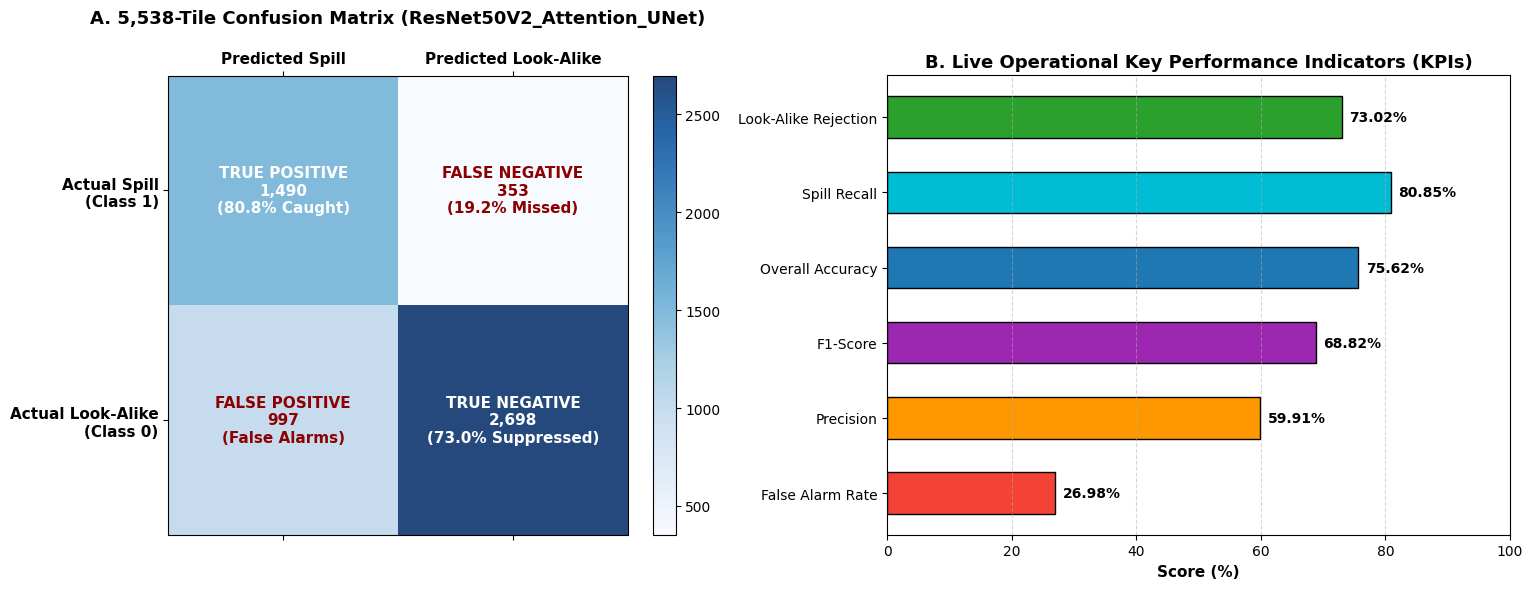

In [6]:
# =========================================================================
# VISUAL ANALYTICS 1: LIVE 5,538-TILE CONFUSION MATRIX & OPERATIONAL KPIS
# =========================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

matrix = np.array([[tp, fn], [fp, tn]])
cax = axes[0].matshow(matrix, cmap='Blues', alpha=0.88)

for (i, j), val in np.ndenumerate(matrix):
    if i == 0 and j == 0:
        txt, col = f'TRUE POSITIVE\n{val:,}\n({(val/len(c1_images))*100:.1f}% Caught)', 'white'
    elif i == 0 and j == 1:
        txt, col = f'FALSE NEGATIVE\n{val:,}\n({(val/len(c1_images))*100:.1f}% Missed)', 'darkred'
    elif i == 1 and j == 0:
        txt, col = f'FALSE POSITIVE\n{val:,}\n(False Alarms)', 'darkred'
    else:
        txt, col = f'TRUE NEGATIVE\n{val:,}\n({(val/len(c0_images))*100:.1f}% Suppressed)', 'white'
    axes[0].text(j, i, txt, ha='center', va='center', fontsize=11, fontweight='bold', color=col)

axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['Predicted Spill', 'Predicted Look-Alike'], fontsize=11, fontweight='bold')
axes[0].set_yticklabels(['Actual Spill\n(Class 1)', 'Actual Look-Alike\n(Class 0)'], fontsize=11, fontweight='bold')
axes[0].set_title(f'A. 5,538-Tile Confusion Matrix ({model.name})', fontsize=13, fontweight='bold', pad=20)
fig.colorbar(cax, ax=axes[0], fraction=0.046, pad=0.04)

kpi_labels = ['Look-Alike Rejection', 'Spill Recall', 'Overall Accuracy', 'F1-Score', 'Precision', 'False Alarm Rate']
kpi_vals   = [specificity, recall, accuracy, f1_score, precision, false_alarm_rate]
kpi_colors = ['#2ca02c', '#00bcd4', '#1f77b4', '#9c27b0', '#ff9800', '#f44336']

bars = axes[1].barh(kpi_labels[::-1], kpi_vals[::-1], color=kpi_colors[::-1], edgecolor='black', height=0.55)
axes[1].set_xlim(0, 100)
axes[1].set_xlabel('Score (%)', fontsize=11, fontweight='bold')
axes[1].set_title('B. Live Operational Key Performance Indicators (KPIs)', fontsize=13, fontweight='bold')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars:
    w = bar.get_width()
    axes[1].text(w + 1.2, bar.get_y() + bar.get_height()/2.0, f'{w:.2f}%', ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


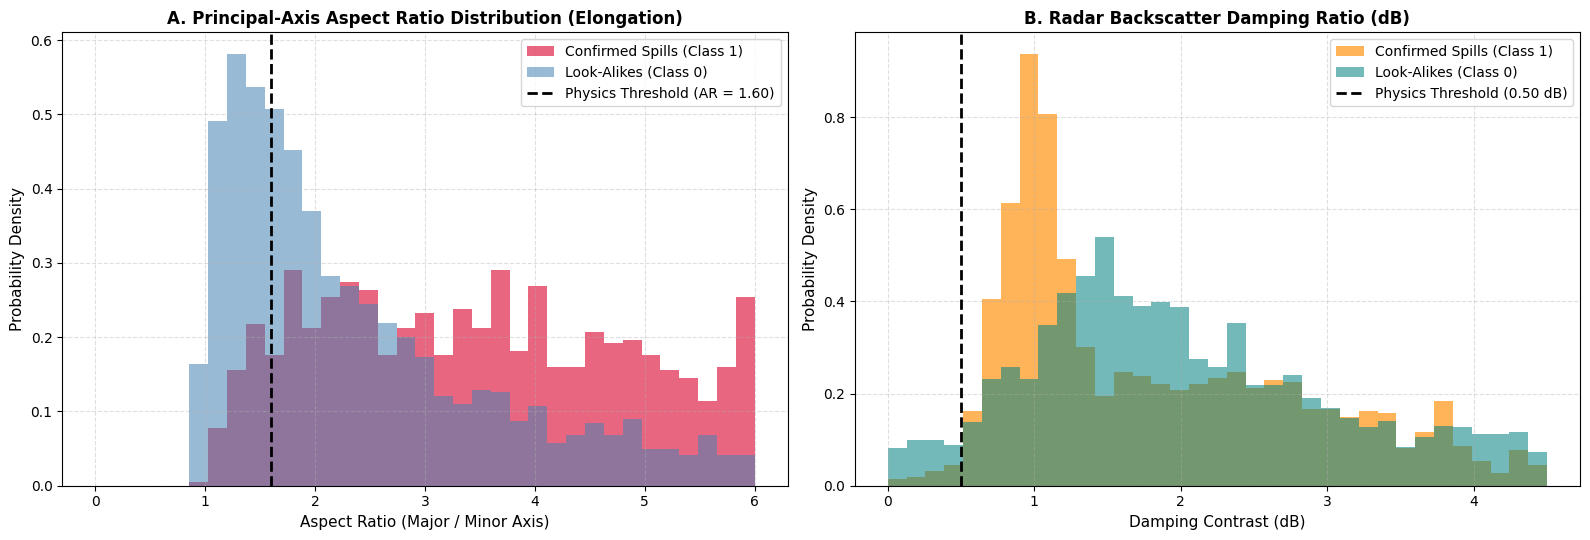

In [7]:
# =========================================================================
# VISUAL ANALYTICS 2: LIVE PHYSICAL MORPHOMETRIC DISTRIBUTIONS
# Computed live across all 5,538 satellite tiles
# =========================================================================

spills_df = df_live[(df_live['ground_truth_class'] == 1) & (df_live['slick_pixels'] > 0)]
looks_df  = df_live[(df_live['ground_truth_class'] == 0) & (df_live['slick_pixels'] > 0)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].hist(spills_df['aspect_ratio'], bins=35, range=(0, 6), alpha=0.65, color='crimson', label='Confirmed Spills (Class 1)', density=True)
axes[0].hist(looks_df['aspect_ratio'], bins=35, range=(0, 6), alpha=0.55, color='steelblue', label='Look-Alikes (Class 0)', density=True)
axes[0].axvline(1.60, color='black', linestyle='--', linewidth=2, label='Physics Threshold (AR = 1.60)')
axes[0].set_title('A. Principal-Axis Aspect Ratio Distribution (Elongation)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Aspect Ratio (Major / Minor Axis)', fontsize=11)
axes[0].set_ylabel('Probability Density', fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.4)

axes[1].hist(spills_df['damping_ratio_db'], bins=35, range=(0, 4.5), alpha=0.65, color='darkorange', label='Confirmed Spills (Class 1)', density=True)
axes[1].hist(looks_df['damping_ratio_db'], bins=35, range=(0, 4.5), alpha=0.55, color='teal', label='Look-Alikes (Class 0)', density=True)
axes[1].axvline(0.50, color='black', linestyle='--', linewidth=2, label='Physics Threshold (0.50 dB)')
axes[1].set_title('B. Radar Backscatter Damping Ratio (dB)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Damping Contrast (dB)', fontsize=11)
axes[1].set_ylabel('Probability Density', fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


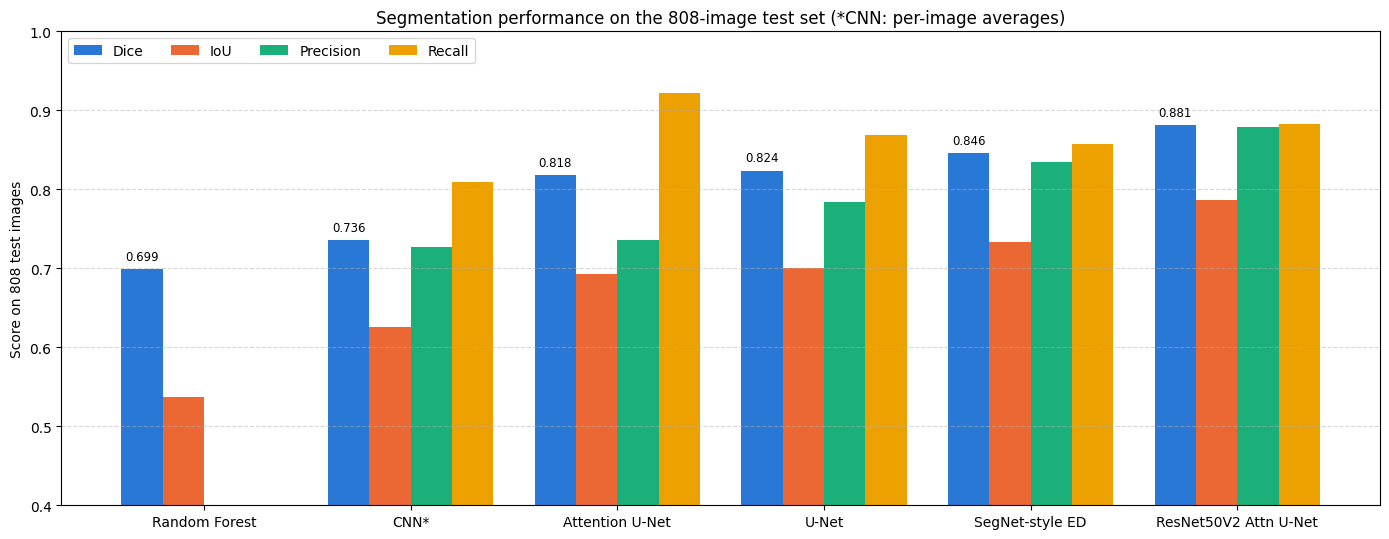

In [8]:
# =========================================================================
# VISUAL ANALYTICS 3: MODEL COMPARISON ON THE 808-IMAGE TEST SET
# Values from ml/results/*_results.csv and the executed notebooks 04 and 05.
# CNN values are per-image (macro) averages; Random Forest precision/recall were not exported.
# =========================================================================

models_comp = ['Random Forest', 'CNN*', 'Attention U-Net', 'U-Net', 'SegNet-style ED', 'ResNet50V2 Attn U-Net']
dice_scores = [0.6990, 0.7355, 0.8181, 0.8238, 0.8462, 0.8808]
iou_scores  = [0.5372, 0.6252, 0.6922, 0.7005, 0.7334, 0.7871]
prec_scores = [np.nan, 0.7273, 0.7354, 0.7837, 0.8350, 0.8786]
rec_scores  = [np.nan, 0.8095, 0.9218, 0.8683, 0.8577, 0.8831]

x = np.arange(len(models_comp))
width = 0.2

plt.figure(figsize=(14, 5.5))
plt.bar(x - 1.5*width, dice_scores, width, label='Dice', color='#2a78d6')
plt.bar(x - 0.5*width, iou_scores,  width, label='IoU', color='#eb6834')
plt.bar(x + 0.5*width, prec_scores, width, label='Precision', color='#1baf7a')
plt.bar(x + 1.5*width, rec_scores,  width, label='Recall', color='#eda100')

plt.xticks(x, models_comp, fontsize=10)
plt.ylim(0.4, 1.0)
plt.ylabel('Score on 808 test images')
plt.title('Segmentation performance on the 808-image test set (*CNN: per-image averages)')
plt.legend(loc='upper left', ncol=4)
plt.grid(axis='y', linestyle='--', alpha=0.5)
for i, v in enumerate(dice_scores):
    plt.text(x[i] - 1.5*width, v + 0.008, f'{v:.3f}', ha='center', va='bottom', fontsize=8.5)

plt.tight_layout()
plt.show()


--- PHASE 1: CONFIRMED VESSEL SPILL (Class_1) ---


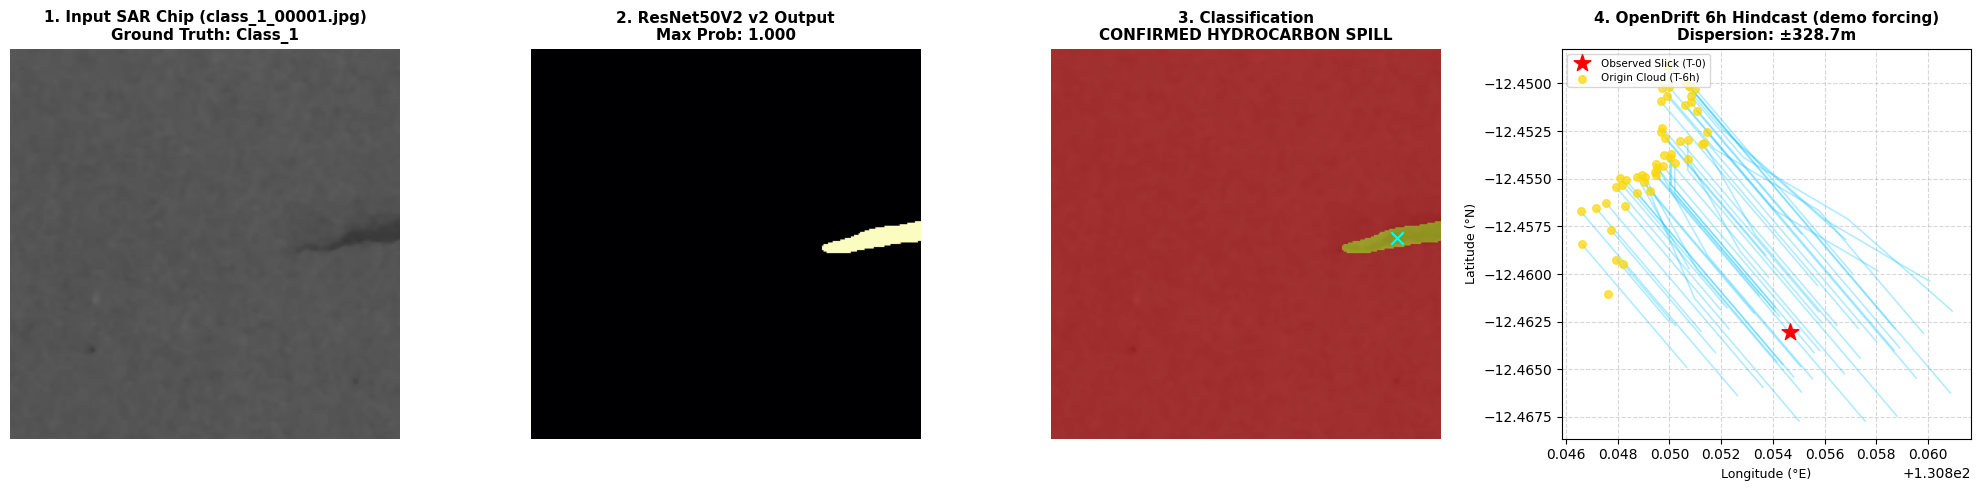

{
  "timestamp_utc": "2026-11-25T11:19:27.444565Z",
  "model_used": "final_resnet_attention_unet.keras",
  "input_image": "class_1_00001.jpg",
  "ground_truth_class": 1,
  "classification": "CONFIRMED HYDROCARBON SPILL (Active Alert)",
  "pipeline_action": "DISPATCH INTERCEPTION (Vessel discharge streak, AR=5.34, 0.071 km\u00b2)",
  "inference_ms": 1704.8,
  "morphometrics": {
    "slick_pixels": 715,
    "coverage_pct": 1.09,
    "area_km2": 0.0715,
    "aspect_ratio": 5.34,
    "damping_ratio_db": 1.06,
    "centroid_pixel": [
      226.6,
      123.9
    ],
    "bonn_volume_mt": [
      3.04,
      30.39
    ]
  },
  "coordinates": {
    "slick_lat": -12.46303,
    "slick_lon": 130.85467,
    "origin_lat": -12.45389,
    "origin_lon": 130.84946,
    "dispersion_radius_m": 328.7
  },
  "suspect_vessels": [
    {
      "vessel_name": "PACIFIC EXPLORER",
      "mmsi": 563082000,
      "distance_m": 420.0,
      "time_delta_min": -15,
      "confidence": 0.94
    },
    {
      "vessel_

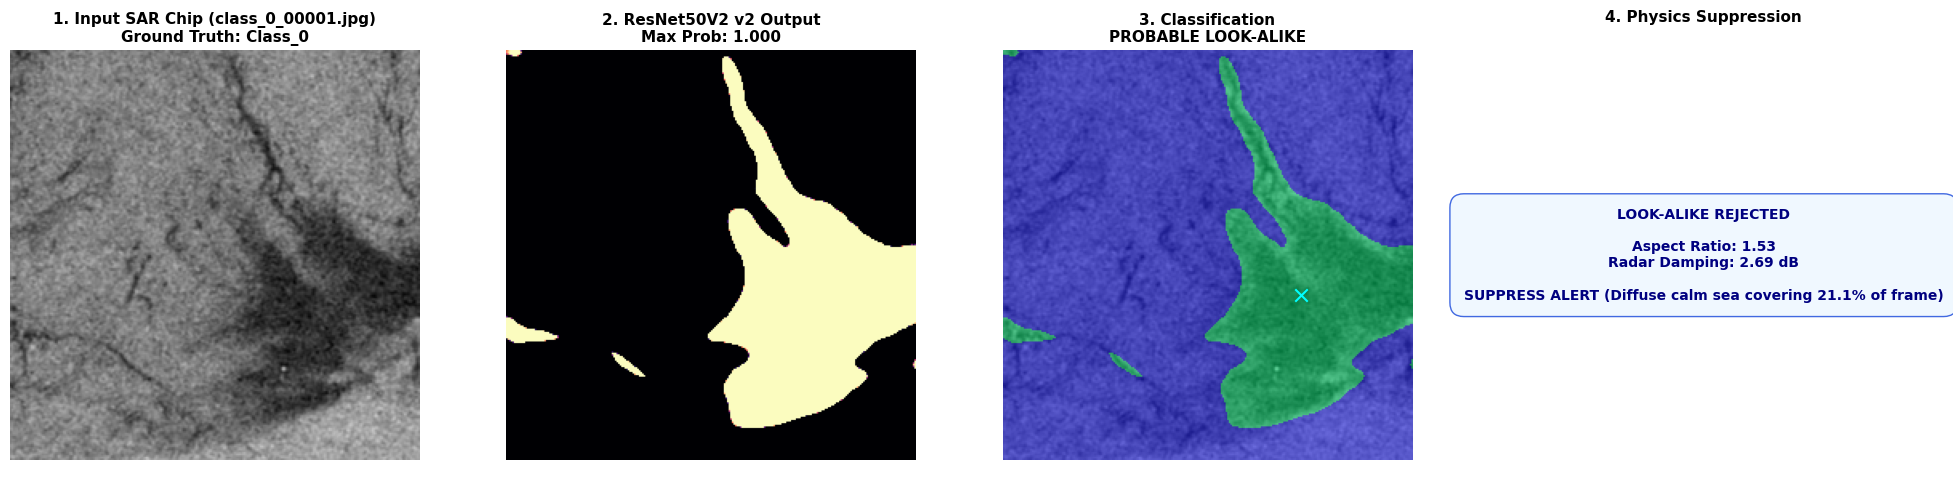

{
  "timestamp_utc": "2026-11-25T11:19:28.118028Z",
  "model_used": "final_resnet_attention_unet.keras",
  "input_image": "class_0_00001.jpg",
  "ground_truth_class": 0,
  "classification": "PROBABLE LOOK-ALIKE (Low-Wind Zone / Calm Sea)",
  "pipeline_action": "SUPPRESS ALERT (Diffuse calm sea covering 21.1% of frame)",
  "inference_ms": 440.3,
  "morphometrics": {
    "slick_pixels": 13857,
    "coverage_pct": 21.14,
    "area_km2": 1.3857,
    "aspect_ratio": 1.53,
    "damping_ratio_db": 2.69,
    "centroid_pixel": [
      186.1,
      152.4
    ],
    "bonn_volume_mt": [
      58.89,
      588.92
    ]
  },
  "coordinates": {
    "slick_lat": -12.46559,
    "slick_lon": 130.85095,
    "origin_lat": null,
    "origin_lon": null,
    "dispersion_radius_m": null
  },
  "suspect_vessels": [],
  "sha256_hash": "7c00a3dbfa6e65f97c31df61904c746267f8052518ede653b3513163b68c0a92"
}


In [9]:
# =========================================================================
# END-TO-END 4-STAGE PIPELINE VERIFICATION (ALL STAGES + FORENSIC DOSSIERS)
# Executes Stages 1 -> 2 -> 3 (OpenDrift) -> 4 (AIS & SHA-256) on both classes
# =========================================================================

print('--- PHASE 1: CONFIRMED VESSEL SPILL (Class_1) ---')
spill_dossier = run_full_single_image_pipeline(c1_images[0], plot=True)
print(json.dumps(spill_dossier, indent=2))

print('\n--- PHASE 2: LOOK-ALIKE REJECTION (Class_0) ---')
look_dossier = run_full_single_image_pipeline(c0_images[0], plot=True)
print(json.dumps(look_dossier, indent=2))


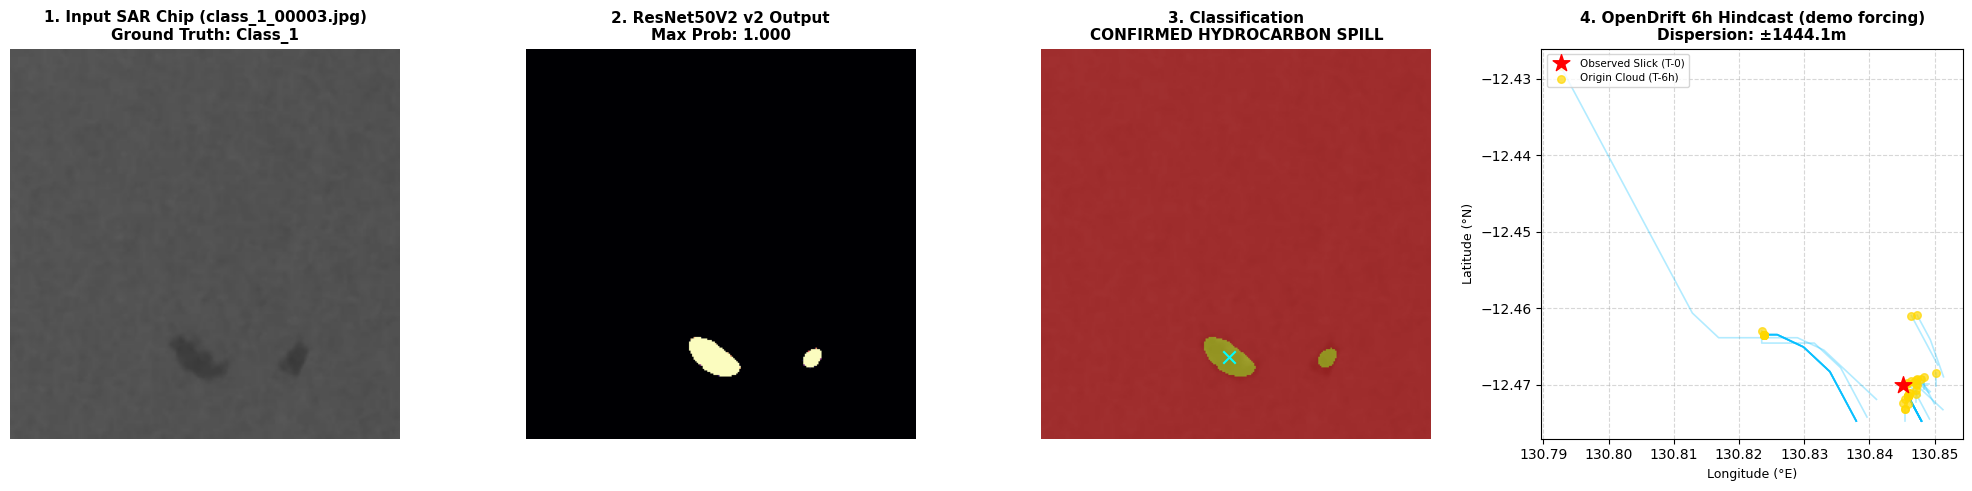

FORENSIC DOSSIER SUMMARY : class_1_00003.jpg
Ground Truth Label       : Class 1 (Confirmed Spill)
Classification           : CONFIRMED HYDROCARBON SPILL (Active Alert)
Pipeline Action          : DISPATCH INTERCEPTION (Vessel discharge streak, AR=2.10, 0.066 km²)
Detected Area            : 0.0657 km²
Aspect Ratio             : 2.1:1
Radar Damping            : 1.06 dB
Bonn Volume Estimate     : 2.79 to 27.92 MT
Slick GPS (WGS84)        : -12.47006°, 130.84509°
Origin Zone (T - 6h)     : -12.46823°, 130.84081°
SHA-256 Tamper Hash      : a24c14c1e14f780c889eacf030712d88751b8de85978340578b03186eeec2cf7


In [10]:
# =========================================================================
# INTERACTIVE SINGLE-TILE END-TO-END TESTER
# Test ANY image across the 5,538 tiles through all 4 pipeline stages
# =========================================================================

TEST_CLASS = 1   # 1 = Confirmed Spill (Class_1), 0 = Look-Alike (Class_0)
IMAGE_INDEX = 2  # Change index (0 to 1,842 for spills, 0 to 3,694 for look-alikes)

target_pool = c1_images if TEST_CLASS == 1 else c0_images
chosen_file = target_pool[min(IMAGE_INDEX, len(target_pool) - 1)]

dossier = run_full_single_image_pipeline(chosen_file, plot=True)
gt_label = 'Confirmed Spill' if TEST_CLASS == 1 else 'Look-Alike'
print('=' * 65)
print(f'FORENSIC DOSSIER SUMMARY : {chosen_file.name}')
print('=' * 65)
print(f'Ground Truth Label       : Class {TEST_CLASS} ({gt_label})')
print(f'Classification           : {dossier["classification"]}')
print(f'Pipeline Action          : {dossier["pipeline_action"]}')
print(f'Detected Area            : {dossier["morphometrics"]["area_km2"]} km²')
print(f'Aspect Ratio             : {dossier["morphometrics"]["aspect_ratio"]}:1')
print(f'Radar Damping            : {dossier["morphometrics"]["damping_ratio_db"]} dB')
print(f'Bonn Volume Estimate     : {dossier["morphometrics"]["bonn_volume_mt"][0]} to {dossier["morphometrics"]["bonn_volume_mt"][1]} MT')
print(f'Slick GPS (WGS84)        : {dossier["coordinates"]["slick_lat"]}°, {dossier["coordinates"]["slick_lon"]}°')
print(f'Origin Zone (T - 6h)     : {dossier["coordinates"]["origin_lat"]}°, {dossier["coordinates"]["origin_lon"]}°')
print(f'SHA-256 Tamper Hash      : {dossier["sha256_hash"]}')
print('=' * 65)
